# Setup

In [ ]:
from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scripts.preprocess import load_csv, normalize_grade_labels

# Read Data

In [ ]:
DATA_DIR = PROJECT_ROOT / "data"
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")
metadata = pd.read_csv(DATA_DIR / "metadata.csv")

print("Train:", train.shape)
display(train.head())

print("\nTest:", test.shape)
display(test.head())

print("\nSample submission:", sample_submission.shape)
display(sample_submission.head())

print("\nMetadata:", metadata.shape)
display(metadata.head())

Train: (533465, 17)


,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,damage_grade,superstructure
0,280803013271,28,2802,280202,3,42,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-2 side,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
1,311908002031,31,3104,310416,2,8,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,Timber-Planck,Not attached,Rectangular,Grade 1,has_superstructure_cement_mortar_brick
2,310303000362,31,3111,311106,2,37,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
3,280806040201,28,2802,280206,2,70,319,15,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,Grade 3,has_superstructure_adobe_mud
4,291301000371,29,2904,290404,1,25,495,6,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Brick/Stone,Not applicable,Not attached,Rectangular,Grade 4,has_superstructure_mud_mortar_stone



Test: (228629, 16)


,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,superstructure
0,122207000141,12,1205,120504,1,8,240,10,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,Not applicable,Not attached,Rectangular,has_superstructure_mud_mortar_stone
1,284909000871,28,2810,281006,3,4,384,22,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,has_superstructure_mud_mortar_stone
2,241904000231,24,2409,240909,2,999,384,21,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,has_superstructure_mud_mortar_stone
3,248308000891,24,2412,241202,2,16,527,19,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,has_superstructure_mud_mortar_stone
4,300405002981,30,3001,300104,2,6,280,16,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,Timber-Planck,Not attached,Rectangular,has_superstructure_mud_mortar_stone



Sample submission: (228629, 2)


,building_id,damage_grade
0,122207000141,Grade 3
1,284909000871,Grade 1
2,241904000231,Grade 5
3,248308000891,Grade 4
4,300405002981,Grade 2



Metadata: (27, 3)


,Variable,Description,Type
0,building_id,A unique ID that identifies a unique building ...,Text
1,district_id,District where the building is located,Text
2,vdcmun_id,Municipality where the building is located,Text
3,ward_id,Ward Number in which the building is located,Text
4,count_floors_pre_eq,Number of floors that the building had before ...,Number


# Informasi Dataset

In [5]:
print("Informasi train:")
train.info()

print("\nInformasi test:")
test.info()

print("\nKolom train:")
print(train.columns.tolist())

print("\nKolom test:")
print(test.columns.tolist())

print("\nMetadata:")
display(metadata.head())

Informasi train:
<class 'pandas.DataFrame'>
RangeIndex: 533465 entries, 0 to 533464
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   building_id             533465 non-null  int64
 1   district_id             533465 non-null  int64
 2   vdcmun_id               533465 non-null  int64
 3   ward_id                 533465 non-null  int64
 4   count_floors_pre_eq     533465 non-null  int64
 5   age_building            533465 non-null  int64
 6   plinth_area_sq_ft       533465 non-null  int64
 7   height_ft_pre_eq        533465 non-null  int64
 8   land_surface_condition  533465 non-null  str  
 9   foundation_type         533465 non-null  str  
 10  roof_type               533465 non-null  str  
 11  ground_floor_type       533465 non-null  str  
 12  other_floor_type        533465 non-null  str  
 13  position                533465 non-null  str  
 14  plan_configuration      533465 non-null  str  

,Variable,Description,Type
0,building_id,A unique ID that identifies a unique building ...,Text
1,district_id,District where the building is located,Text
2,vdcmun_id,Municipality where the building is located,Text
3,ward_id,Ward Number in which the building is located,Text
4,count_floors_pre_eq,Number of floors that the building had before ...,Number


# Statistik Deskriptif

In [7]:
display(train.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
building_id,533465.0,NaN,NaN,NaN,260713869440.823547,58065626050.503632,120101000011.0,221906000941.0,246301000211.0,303607000571.0,366709001251.0
district_id,533465.0,NaN,NaN,NaN,25.764134,5.81223,12.0,22.0,24.0,30.0,36.0
vdcmun_id,533465.0,NaN,NaN,NaN,2582.312433,581.640567,1201.0,2204.0,2410.0,3010.0,3611.0
ward_id,533465.0,NaN,NaN,NaN,258236.686092,58164.132189,120101.0,220401.0,241004.0,301005.0,361108.0
count_floors_pre_eq,533465.0,NaN,NaN,NaN,2.088,0.655001,1.0,2.0,2.0,2.0,9.0
age_building,533465.0,NaN,NaN,NaN,24.337319,64.999055,0.0,9.0,16.0,27.0,999.0
plinth_area_sq_ft,533465.0,NaN,NaN,NaN,406.523453,226.610477,70.0,280.0,358.0,470.0,5000.0
height_ft_pre_eq,533465.0,NaN,NaN,NaN,16.047675,5.490926,6.0,12.0,16.0,18.0,99.0
land_surface_condition,533465,3,Flat,442089,NaN,NaN,NaN,NaN,NaN,NaN,NaN
foundation_type,533465,5,Mud mortar-Stone/Brick,440105,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Cek Missing Value

In [6]:
missing_train = pd.DataFrame({
    "missing_count": train.isna().sum(),
    "missing_percent": (train.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)

missing_test = pd.DataFrame({
    "missing_count": test.isna().sum(),
    "missing_percent": (test.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)

print("Missing values train:")
display(missing_train[missing_train["missing_count"] > 0])

print("Missing values test:")
display(missing_test[missing_test["missing_count"] > 0])

Missing values train:


,missing_count,missing_percent


Missing values test:


,missing_count,missing_percent


# Cek Duplikasi

In [8]:
print("Jumlah duplikasi baris train:", train.duplicated().sum())

if "building_id" in train.columns:
    print("Duplikasi building_id train:", train["building_id"].duplicated().sum())

if "building_id" in test.columns:
    print("Duplikasi building_id test:", test["building_id"].duplicated().sum())

Jumlah duplikasi baris train: 0
Duplikasi building_id train: 0
Duplikasi building_id test: 0


# Distribusi Target

Jumlah kelas:


damage_grade
Grade 1     55170
Grade 2     61080
Grade 3     95488
Grade 4    128691
Grade 5    193036
Name: count, dtype: int64

Persentase kelas:


damage_grade
Grade 1    10.34
Grade 2    11.45
Grade 3    17.90
Grade 4    24.12
Grade 5    36.19
Name: proportion, dtype: float64

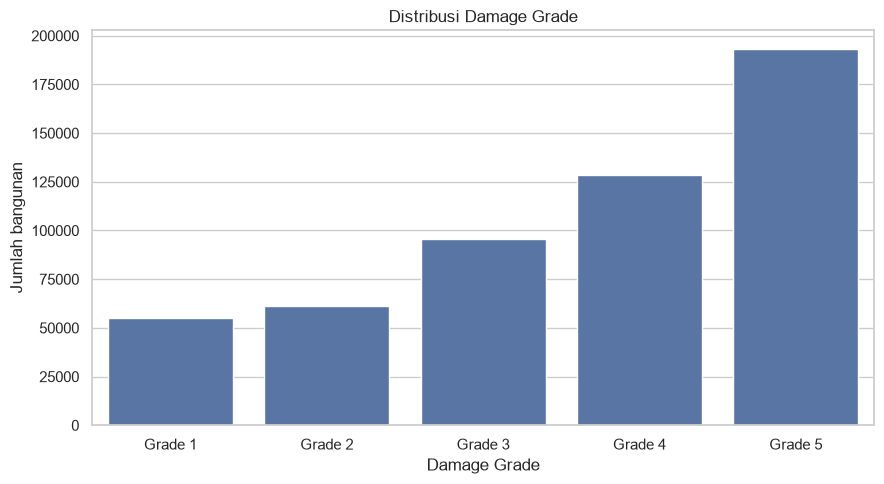

In [11]:
TARGET = "damage_grade"

print("Jumlah kelas:")
display(train[TARGET].value_counts(dropna=False).sort_index())

print("Persentase kelas:")
display((train[TARGET].value_counts(normalize=True, dropna=False).sort_index() * 100).round(2))

plt.figure(figsize=(9, 5))
sns.countplot(data=train, x=TARGET,
              order=sorted(train[TARGET].dropna().unique())
)
plt.title("Distribusi Damage Grade")
plt.xlabel("Damage Grade")
plt.ylabel("Jumlah bangunan")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "target_distribution.png", dpi=150)
plt.show()

# Pisahkan fitur numerik dan kategorikal

In [12]:
ID_COL = "building_id"

X_eda = train.drop(columns=[TARGET, ID_COL], errors="ignore")

geo_cols = [col for col in ["district_id", "vdcmun_id", "ward_id"] if col in X_eda.columns]

for col in geo_cols:
    X_eda[col] = X_eda[col].astype("string")

numeric_cols = X_eda.select_dtypes(include=np.number).columns.tolist()

categorical_cols = X_eda.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

print("Fitur numerik:", numeric_cols)
print("\nFitur kategorikal:", categorical_cols)

Fitur numerik: ['count_floors_pre_eq', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq']

Fitur kategorikal: ['district_id', 'vdcmun_id', 'ward_id', 'land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'superstructure']


# NUMERIK

## Distribusi fitur numerik

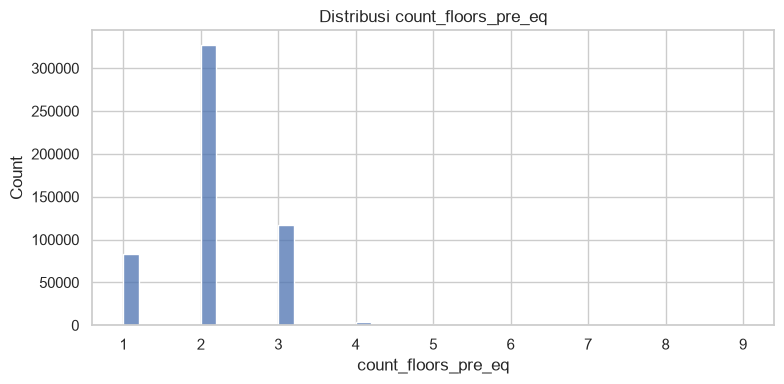

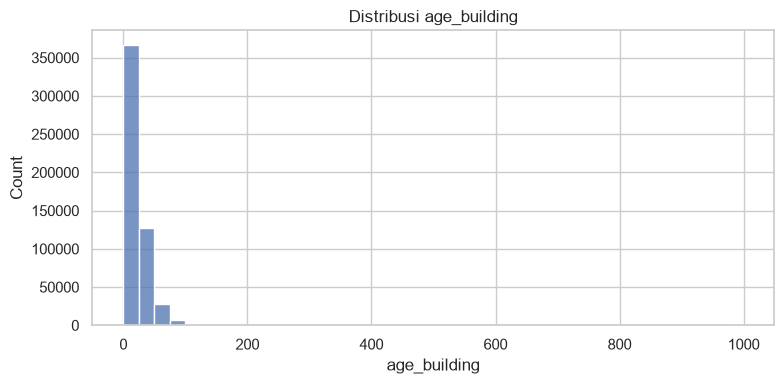

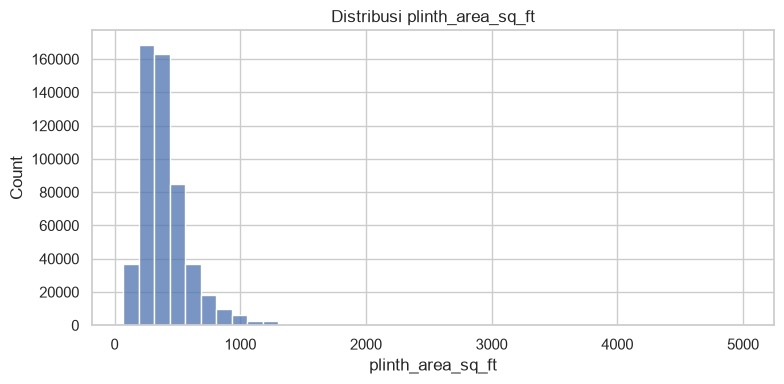

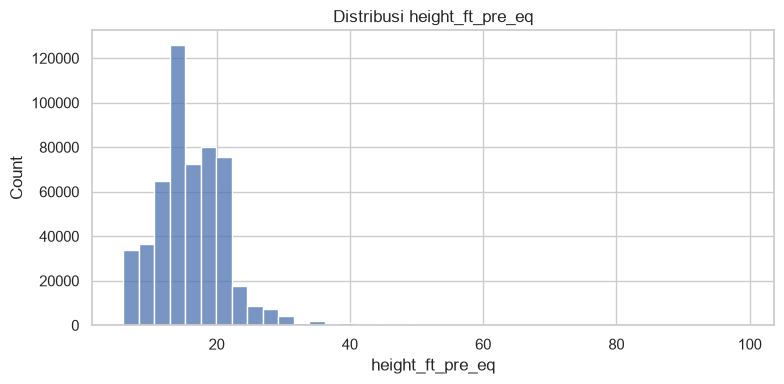

In [13]:
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=X_eda, x=col, bins=40)
    plt.title(f"Distribusi {col}")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"distribution_{col}.png", dpi=150)
    plt.show()

## Hubungan fitur numerik dengan target

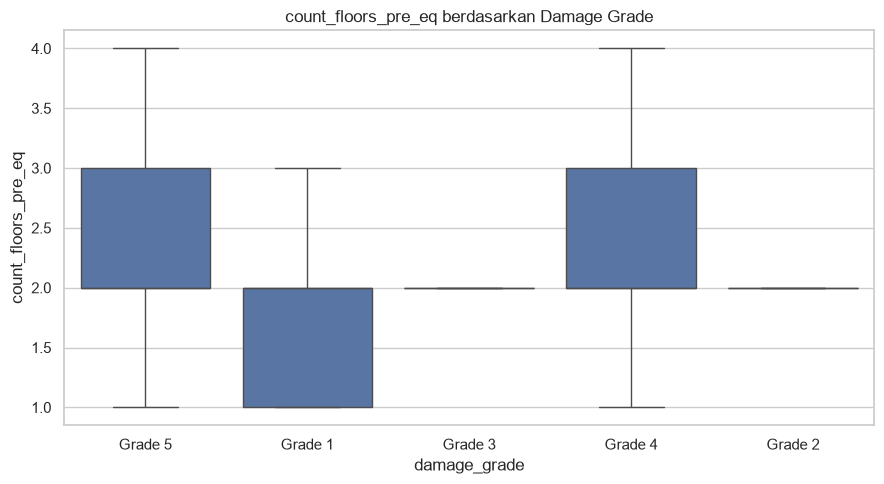

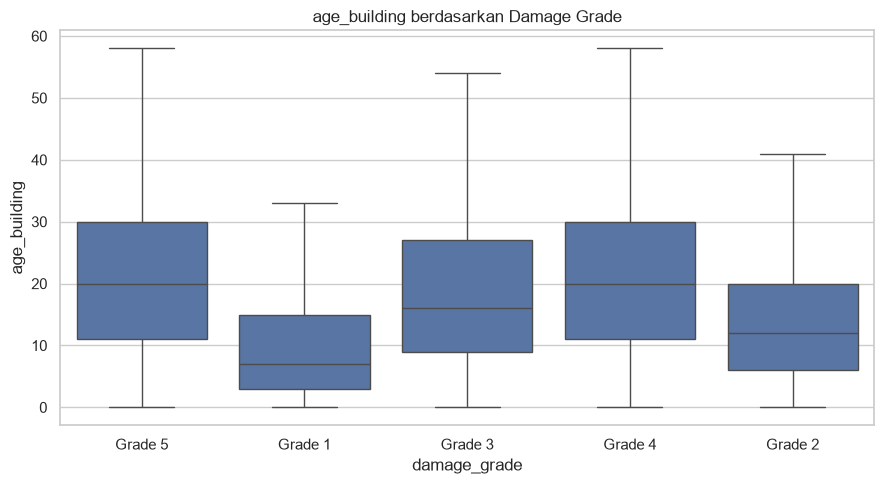

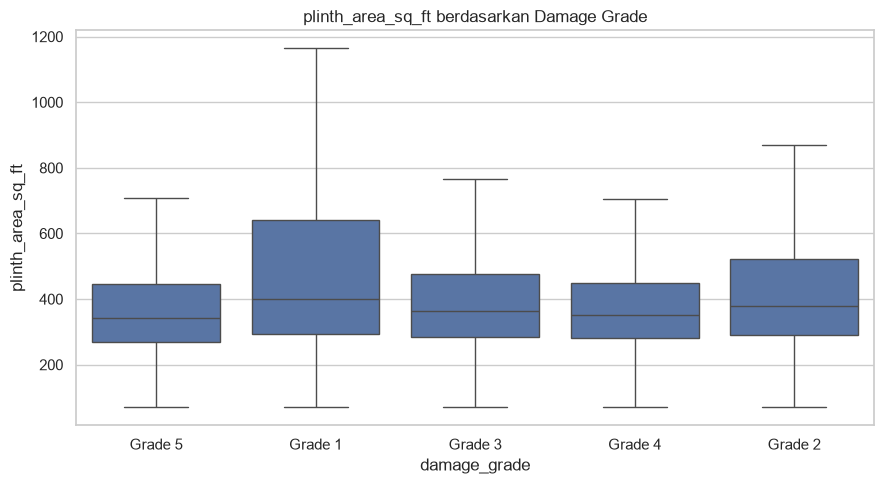

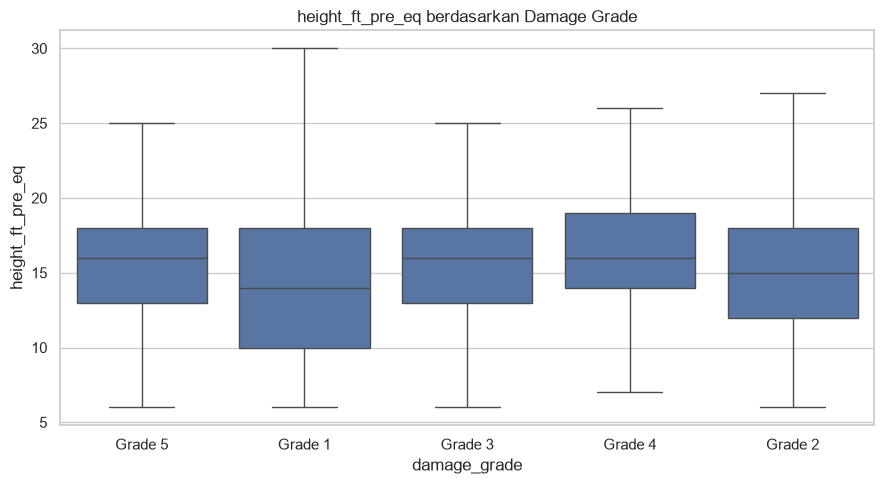

In [ ]:
for col in numeric_cols:
    plt.figure(figsize=(9, 5))
    sns.boxplot(data=train, x=TARGET, y=col, showfliers=False)
    plt.title(f"{col} berdasarkan Damage Grade")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"{col}_by_damage_grade.png", dpi=150)
    plt.show()

# KATEGORIKAL

## Distribusi fitur kategorikal


Kolom: district_id


district_id
24    68616
31    63557
30    62461
23    62165
36    54751
28    53704
20    48133
22    42465
21    41095
12    27651
29     8867
Name: count, dtype: int64

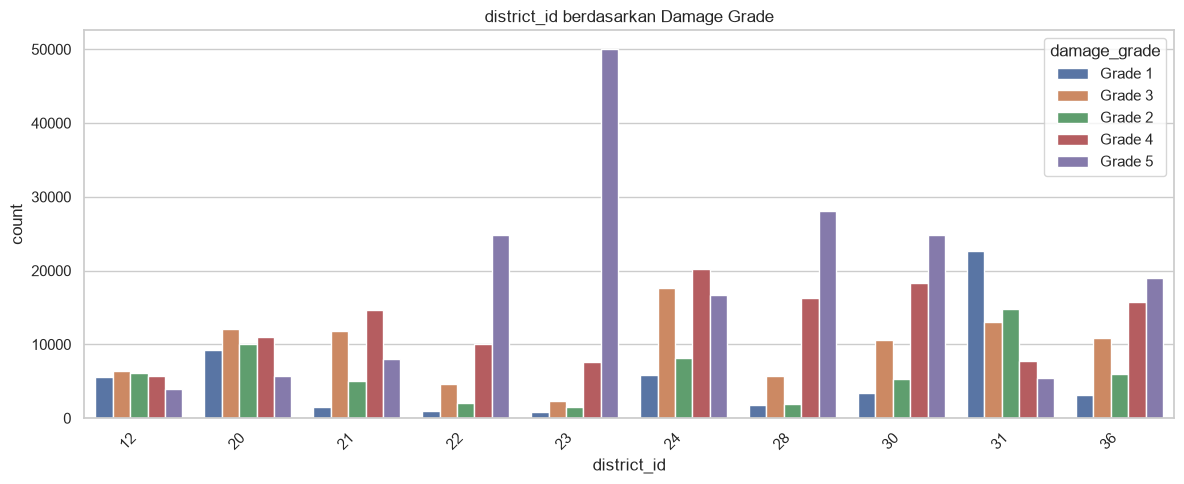


Kolom: vdcmun_id


vdcmun_id
3104    22770
2005    10946
3009    10718
2802    10590
2001    10510
2304    10176
2310     9705
2105     9456
3608     9296
2410     8607
2401     8406
3609     8200
2411     7671
2202     7600
2801     7518
Name: count, dtype: int64

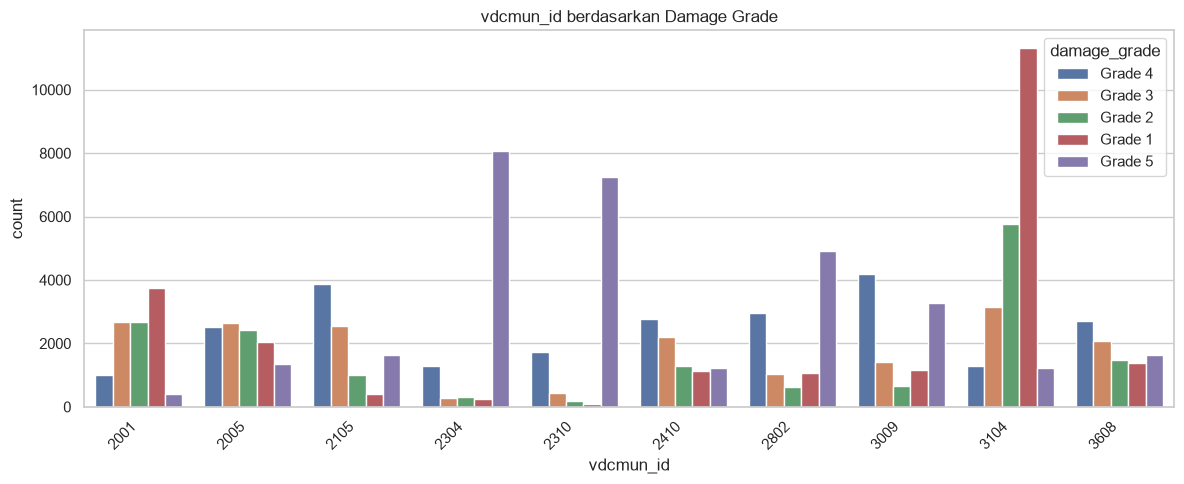


Kolom: ward_id


ward_id
310405    1803
310404    1692
310412    1599
200506    1442
310419    1380
310411    1378
241004    1331
310415    1330
310409    1321
310408    1280
300903    1270
310418    1260
280213    1200
310413    1194
360304    1161
Name: count, dtype: int64

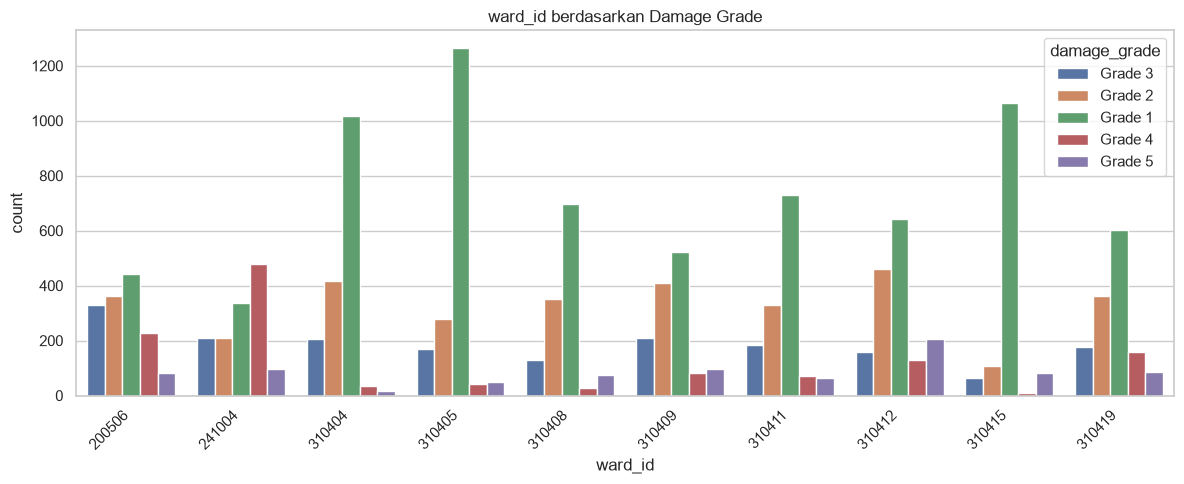


Kolom: land_surface_condition


land_surface_condition
Flat              442089
Moderate slope     73944
Steep slope        17432
Name: count, dtype: int64

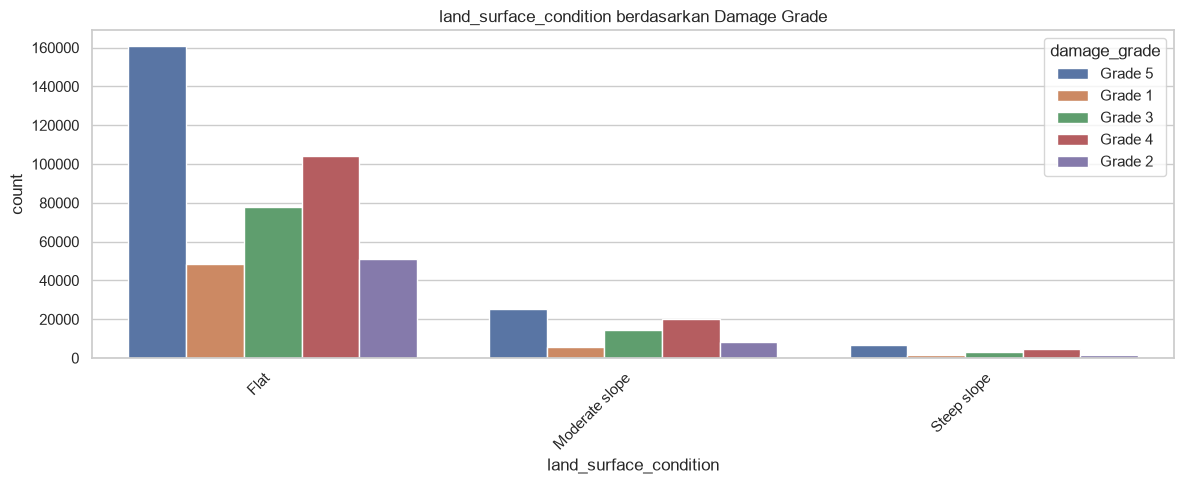


Kolom: foundation_type


foundation_type
Mud mortar-Stone/Brick    440105
Bamboo/Timber              40167
Cement-Stone/Brick         27562
RC                         22445
Other                       3186
Name: count, dtype: int64

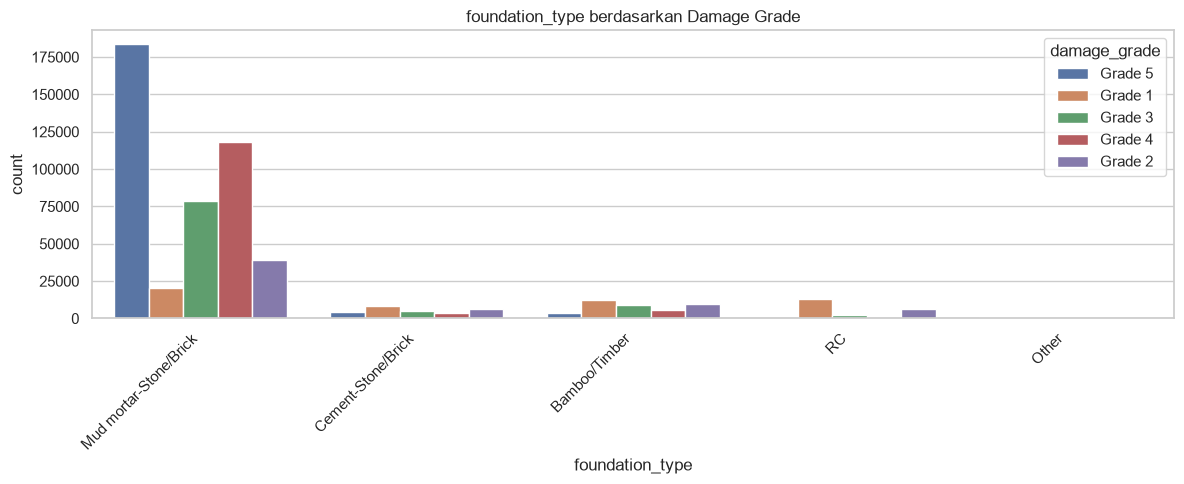


Kolom: roof_type


roof_type
Bamboo/Timber-Light roof    352493
Bamboo/Timber-Heavy roof    149836
RCC/RB/RBC                   31136
Name: count, dtype: int64

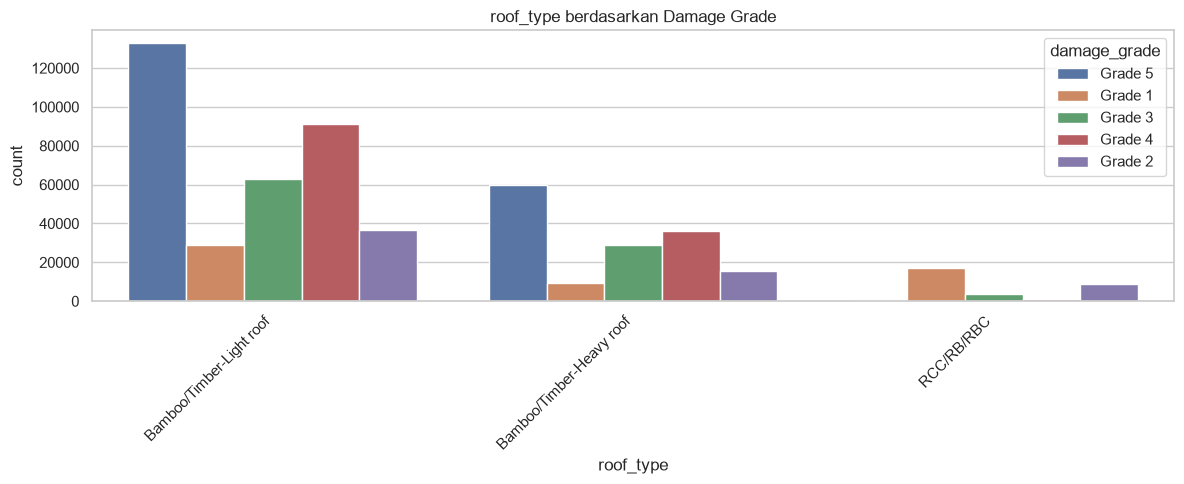


Kolom: ground_floor_type


ground_floor_type
Mud            432806
RC              51146
Brick/Stone     46264
Timber           2507
Other             742
Name: count, dtype: int64

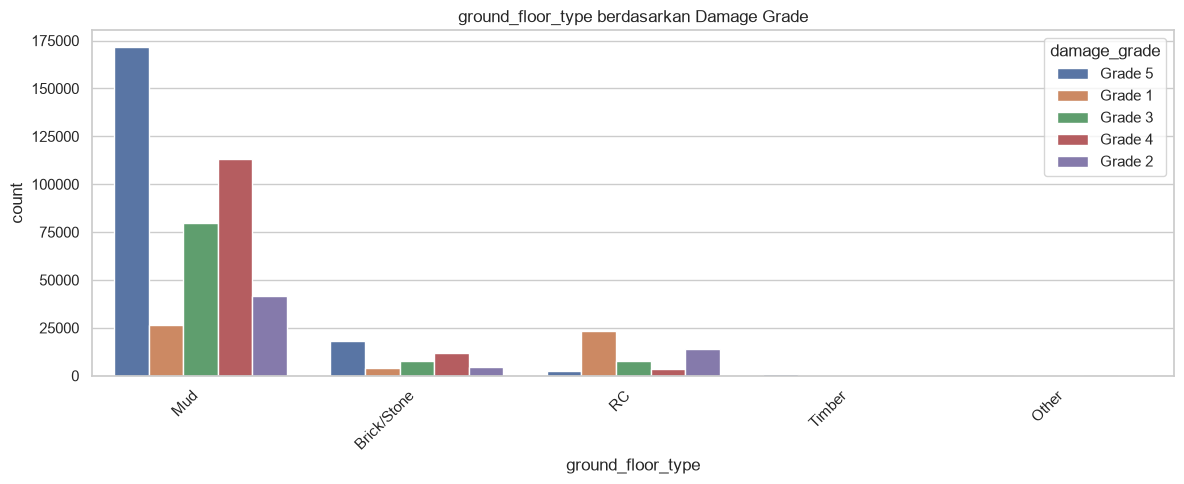


Kolom: other_floor_type


other_floor_type
TImber/Bamboo-Mud    340906
Timber-Planck         86637
Not applicable        83103
RCC/RB/RBC            22819
Name: count, dtype: int64

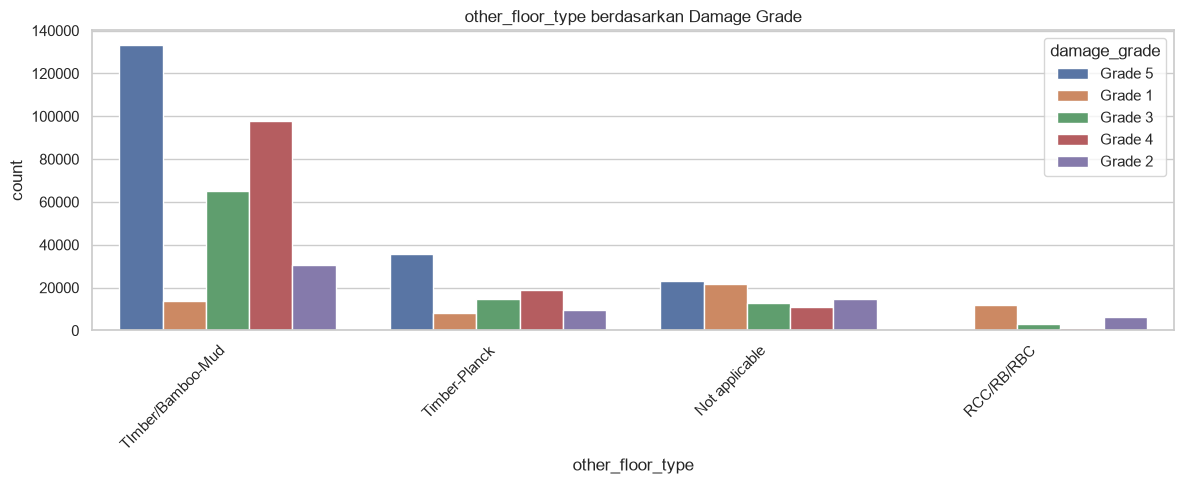


Kolom: position


position
Not attached       423151
Attached-1 side     90493
Attached-2 side     18943
Attached-3 side       878
Name: count, dtype: int64

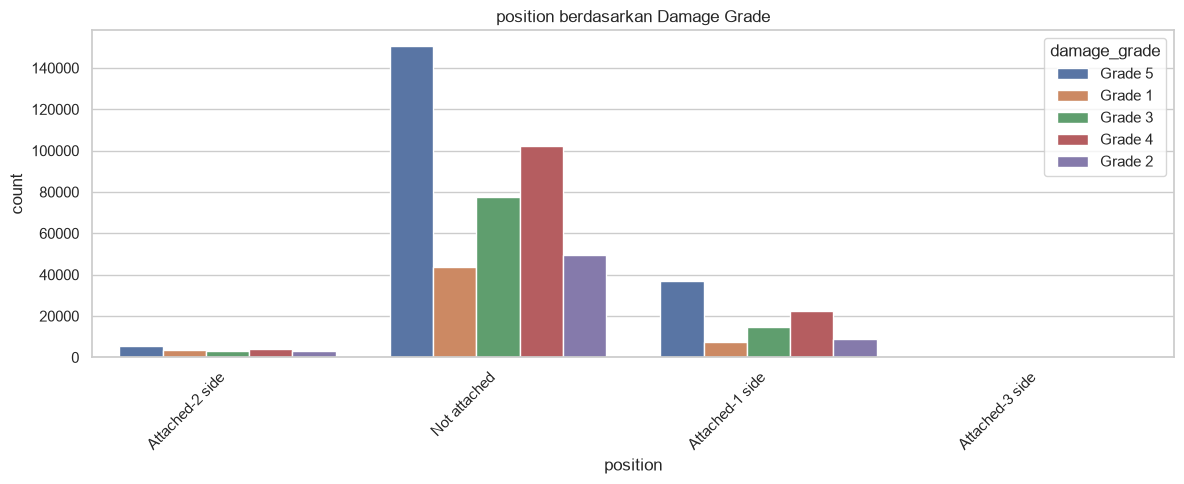


Kolom: plan_configuration


plan_configuration
Rectangular                        511999
Square                              12229
L-shape                              7009
T-shape                               668
Multi-projected                       636
Others                                387
U-shape                               313
E-shape                                99
Building with Central Courtyard        64
H-shape                                61
Name: count, dtype: int64

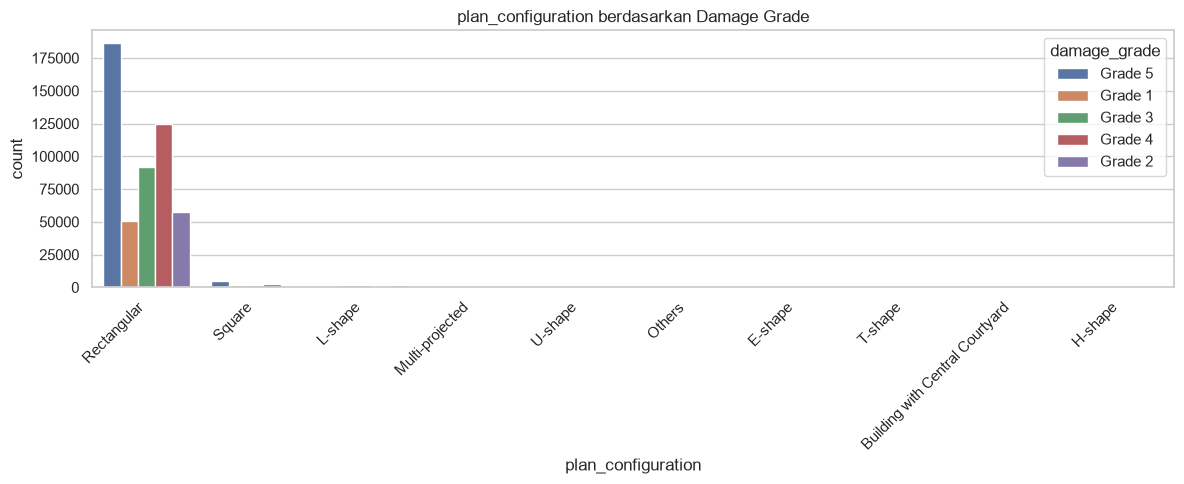


Kolom: superstructure


superstructure
has_superstructure_mud_mortar_stone       415327
has_superstructure_cement_mortar_brick     33289
has_superstructure_timber                  25407
has_superstructure_adobe_mud               22574
has_superstructure_rc_non_engineered        9051
has_superstructure_stone_flag               6994
has_superstructure_mud_mortar_brick         6746
has_superstructure_rc_engineered            5475
has_superstructure_cement_mortar_stone      4946
has_superstructure_bamboo                   2788
has_superstructure_other                     868
Name: count, dtype: int64

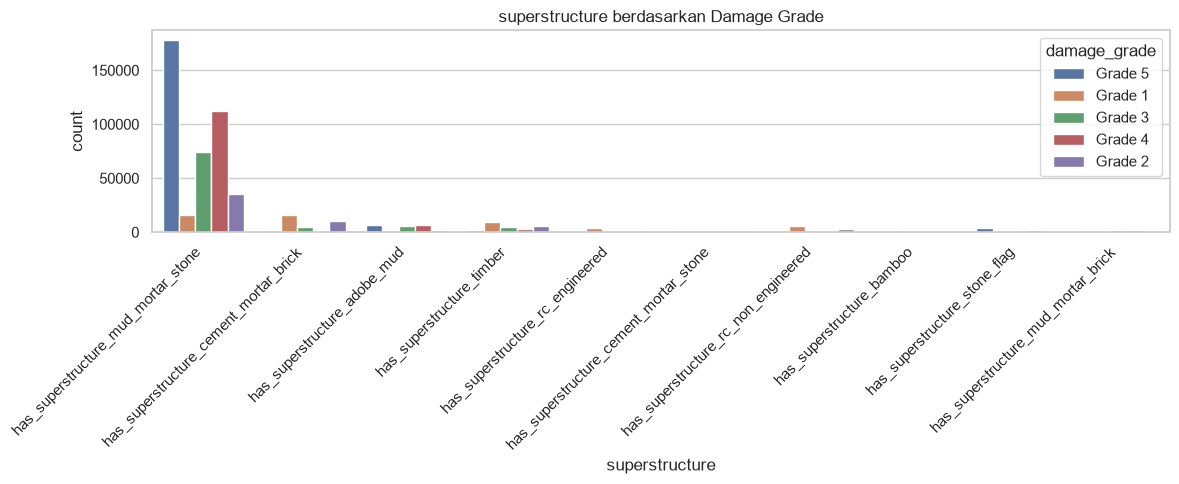

In [15]:
for col in categorical_cols:
    print(f"\nKolom: {col}")
    display(train[col].value_counts(dropna=False).head(15))

    top_categories = train[col].value_counts().head(10).index
    plot_data = train[train[col].isin(top_categories)]

    plt.figure(figsize=(12, 5))
    sns.countplot(data=plot_data, x=col, hue=TARGET)
    plt.title(f"{col} berdasarkan Damage Grade")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"{col}_by_damage_grade.png", dpi=150)
    plt.show()

# Simpan ringkasan EDA

In [16]:
summary = pd.DataFrame({
    "metric": [
        "train_rows",
        "train_columns",
        "test_rows",
        "test_columns",
        "target_classes",
        "duplicate_train_rows",
        "missing_train_cells",
        "missing_test_cells"
    ],
    "value": [
        len(train),
        train.shape[1],
        len(test),
        test.shape[1],
        train[TARGET].nunique(),
        int(train.duplicated().sum()),
        int(train.isna().sum().sum()),
        int(test.isna().sum().sum())
    ]
})

display(summary)

summary.to_csv(ROOT_DIR / "reports" / "eda_summary.csv", index=False)

,metric,value
0,train_rows,533465
1,train_columns,17
2,test_rows,228629
3,test_columns,16
4,target_classes,5
5,duplicate_train_rows,0
6,missing_train_cells,0
7,missing_test_cells,0
